# Week 6 — Decision Trees and Random Forests, plus the Final Model Comparison

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** charge-off (1) vs fully paid (0), with the same features and the same train/test split as Weeks 4–5.

Questions:
1. Does a decision tree find useful thresholds and interactions, and how quickly does it overfit as depth grows?
2. Does a random forest (many decorrelated trees, averaged) improve on a single tree and on the linear models?
3. Across Weeks 4–6, which model is best on the **identical** test loans, and is the difference large enough to matter?

**Key ideas**
* A **decision tree** splits the data with if/then rules chosen to reduce impurity (Gini). It needs no scaling and captures interactions automatically, but a deep tree memorizes noise. Depth, minimum leaf size, and cost-complexity pruning control complexity.
* A **random forest** trains many trees on bootstrap samples, each split considering only a random subset of features (`max_features`). Averaging decorrelated trees lowers variance. **Out-of-bag (OOB)** rows, the ones each tree did not see, give a built-in validation estimate.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, validation_curve, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score, recall_score,
                             f1_score, accuracy_score, precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
RF_TUNE_N = 50_000     # training-row subsample for the forest's randomized search
N_JOBS = -1

NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train["target"].astype(int)
X_te, y_te = test[NUM + CAT], test["target"].astype(int)
print(f"train {X_tr.shape} | test {X_te.shape}")

def make_pre():   # trees need no scaling
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), NUM),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), CAT),
    ])

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC(AP)": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "threshold": thr}

def f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f[:-1])])

CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
CV3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

scikit-learn 1.6.1


train (140000, 24) | test (60000, 24)


## 1. Decision tree: complexity vs generalization

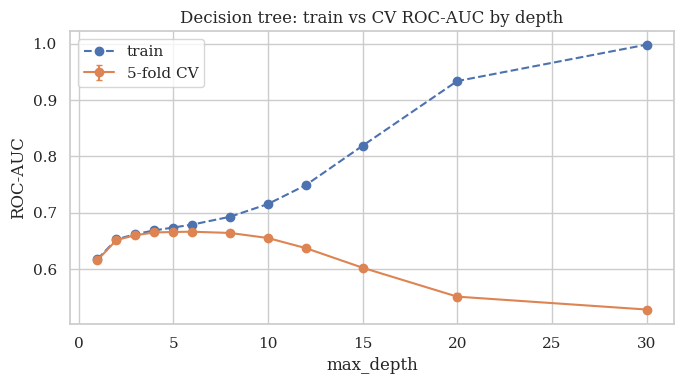

,max_depth,train,cv,gap
0,1,0.6175,0.6158,0.0018
1,2,0.6525,0.6514,0.0011
2,3,0.6620,0.6601,0.0020
3,4,0.6686,0.6649,0.0037
4,5,0.6738,0.6659,0.0079
5,6,0.6789,0.6663,0.0126
6,8,0.6929,0.6641,0.0288
7,10,0.7154,0.6551,0.0603
8,12,0.7490,0.6372,0.1118
9,15,0.8190,0.6023,0.2167


In [2]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
tree_pipe = Pipeline([("pre", make_pre()), ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE))])
tr_sc, cv_sc = validation_curve(tree_pipe, X_tr, y_tr, param_name="tree__max_depth", param_range=depths,
                                cv=CV5, scoring="roc_auc", n_jobs=N_JOBS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, tr_sc.mean(1), marker="o", ls="--", label="train")
ax.errorbar(depths, cv_sc.mean(1), yerr=cv_sc.std(1), marker="o", capsize=2, label="5-fold CV")
ax.set(xlabel="max_depth", ylabel="ROC-AUC", title="Decision tree: train vs CV ROC-AUC by depth"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "week6_tree_depth_curve.png", dpi=200); plt.show()
pd.DataFrame({"max_depth": depths, "train": tr_sc.mean(1), "cv": cv_sc.mean(1), "gap": tr_sc.mean(1) - cv_sc.mean(1)})

In [3]:
# Tune depth together with minimum leaf size (a second guard against overfitting)
tree_search = GridSearchCV(tree_pipe, {"tree__max_depth": [4, 6, 8, 10, 12], "tree__min_samples_leaf": [20, 100, 500],
                                       "tree__class_weight": [None, "balanced"]},
                           scoring="roc_auc", cv=CV5, return_train_score=True, n_jobs=N_JOBS)
t0 = time.time(); tree_search.fit(X_tr, y_tr); print(f"tree search {time.time()-t0:.0f}s")
print("Best tree:", tree_search.best_params_, f"CV ROC-AUC {tree_search.best_score_:.4f}")
best_tree = tree_search.best_estimator_

tree search 38s
Best tree: {'tree__class_weight': None, 'tree__max_depth': 8, 'tree__min_samples_leaf': 500} CV ROC-AUC 0.6681


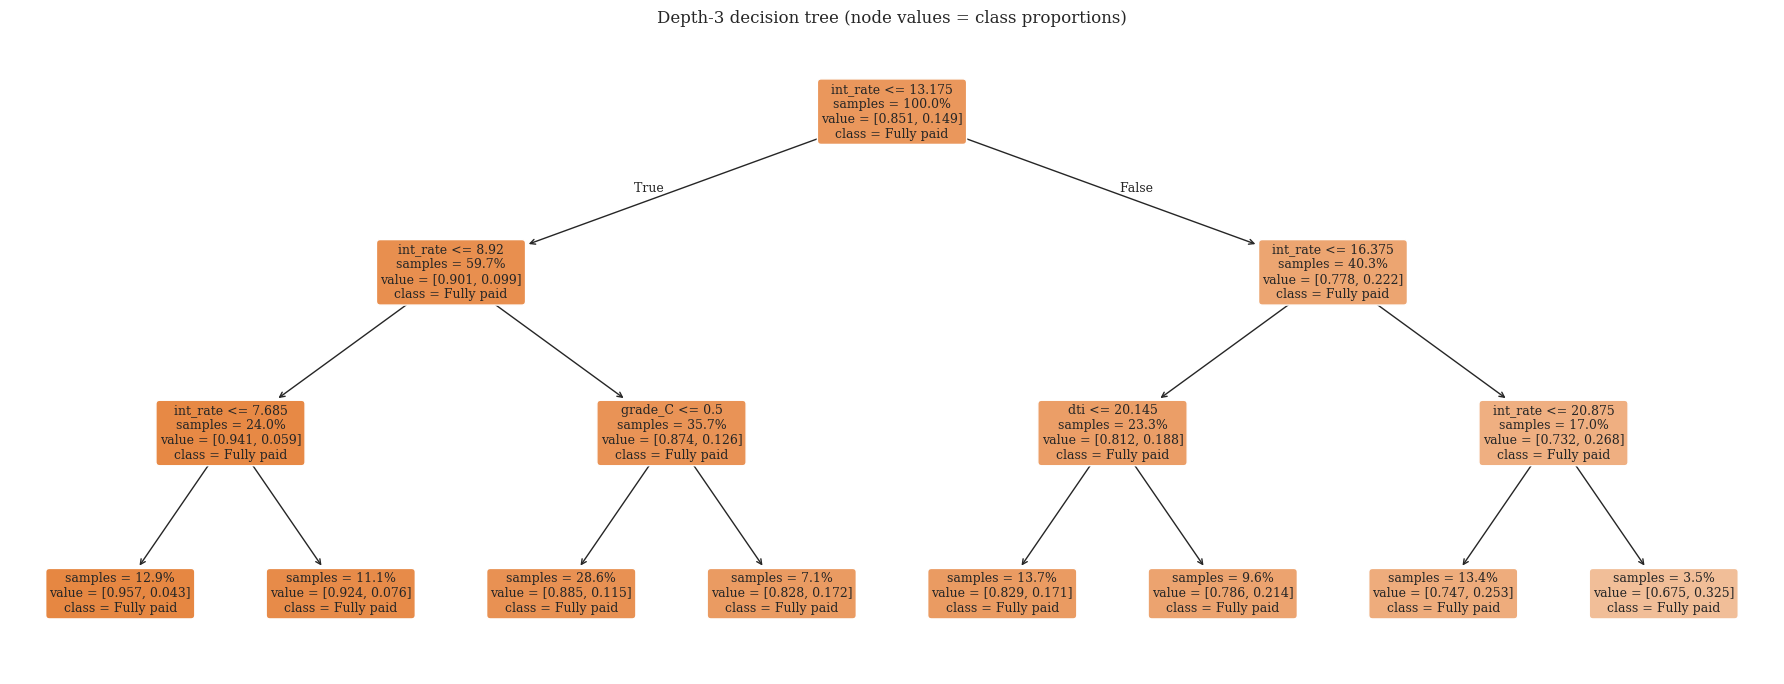

In [4]:
# An interpretable depth-3 tree (for explanation only, not the tuned model)
small = Pipeline([("pre", make_pre()), ("tree", DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
fnames = [n.split("__", 1)[-1] for n in small["pre"].get_feature_names_out()]
plt.figure(figsize=(18, 7))
plot_tree(small["tree"], feature_names=fnames, class_names=["Fully paid", "Charged off"], filled=True,
          proportion=True, impurity=False, rounded=True, fontsize=9)
plt.title("Depth-3 decision tree (node values = class proportions)")
plt.tight_layout(); plt.savefig(FIG_DIR / "week6_tree_depth3.png", dpi=200); plt.show()

## 2. Random forest

A randomized search over depth, leaf size, `max_features`, and class weighting runs on a 50,000-row training subsample (3-fold CV, 150 trees). The best settings are then refit on the full training set with 400 trees and OOB scoring.

In [5]:
if RF_TUNE_N < len(X_tr):
    X_rt, _, y_rt, _ = train_test_split(X_tr, y_tr, train_size=RF_TUNE_N, stratify=y_tr, random_state=RANDOM_STATE)
else:
    X_rt, y_rt = X_tr, y_tr
rf_dist = {"rf__max_depth": [8, 12, 16, 24, None], "rf__min_samples_leaf": [1, 5, 20, 50, 100],
           "rf__max_features": ["sqrt", 0.3, 0.5], "rf__class_weight": [None, "balanced_subsample"]}
rf_search = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("rf", RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=N_JOBS))]),
                               rf_dist, n_iter=12, scoring="roc_auc", cv=CV3, return_train_score=True, random_state=RANDOM_STATE)
t0 = time.time(); rf_search.fit(X_rt, y_rt); print(f"RF search {time.time()-t0:.0f}s")
rf_res = pd.DataFrame(rf_search.cv_results_)
rf_res["gap"] = rf_res["mean_train_score"] - rf_res["mean_test_score"]
for c in [c for c in rf_res.columns if c.startswith("param_")]:
    rf_res[c] = rf_res[c].map(str)
rf_res.filter(regex="param_|mean_train_score|mean_test_score|gap").sort_values("mean_test_score", ascending=False).head(8)

RF search 71s


,param_rf__min_samples_leaf,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,mean_test_score,mean_train_score,gap
1,50,sqrt,12,None,0.6865,0.7552,0.0687
6,100,sqrt,None,None,0.6861,0.7316,0.0454
8,50,0.3,None,None,0.6853,0.7946,0.1093
3,50,sqrt,8,balanced_subsample,0.6850,0.7230,0.0380
0,50,0.5,None,None,0.6843,0.8064,0.1221
11,20,0.5,8,None,0.6839,0.7536,0.0697
9,20,0.3,8,balanced_subsample,0.6837,0.7463,0.0626
2,50,0.5,16,balanced_subsample,0.6834,0.8130,0.1296


In [6]:
best_rf_params = {k.replace("rf__", ""): v for k, v in rf_search.best_params_.items()}
rf = Pipeline([("pre", make_pre()), ("rf", RandomForestClassifier(n_estimators=400, oob_score=True, random_state=RANDOM_STATE,
                                                                  n_jobs=N_JOBS, **best_rf_params))])
t0 = time.time(); rf.fit(X_tr, y_tr); rf_secs = time.time() - t0
oob_auc = roc_auc_score(y_tr, rf["rf"].oob_decision_function_[:, 1])
s_rf_tr = rf.predict_proba(X_tr)[:, 1]
s_rf_te = rf.predict_proba(X_te)[:, 1]
print(f"RF params {best_rf_params} | fit {rf_secs:.0f}s")
print(f"ROC-AUC  train (in-sample) {roc_auc_score(y_tr, s_rf_tr):.4f} | OOB {oob_auc:.4f} | test {roc_auc_score(y_te, s_rf_te):.4f}")

RF params {'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None} | fit 17s
ROC-AUC  train (in-sample) 0.7259 | OOB 0.6836 | test 0.6823


**Reading the overfitting check:** a forest's in-sample training AUC is nearly always inflated, because each tree has seen most of those rows. The **OOB** AUC is the honest internal estimate, and it should be close to the test AUC.

## 3. What drives the forest's predictions?

* **Impurity (MDI) importance** comes from the training fit. It is fast, but it is biased toward continuous, high-cardinality features.
* **Permutation importance** measures how much test ROC-AUC drops when a single *original* variable is shuffled (a 20,000-row test subsample, 5 repeats). It is used only to interpret the model, never to choose it.

permutation importance 17s


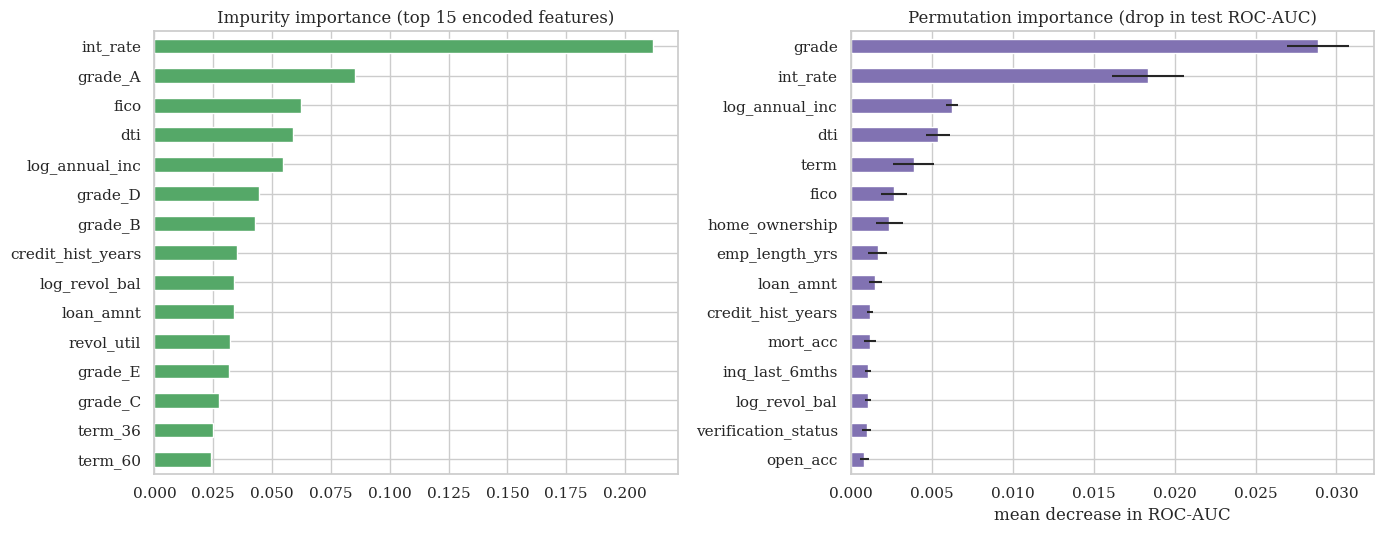

In [7]:
mdi = pd.Series(rf["rf"].feature_importances_, index=[n.split("__", 1)[-1] for n in rf["pre"].get_feature_names_out()]).sort_values(ascending=False)
rng = np.random.default_rng(RANDOM_STATE)
pi_idx = rng.choice(len(X_te), size=min(20_000, len(X_te)), replace=False)
t0 = time.time()
pi = permutation_importance(rf, X_te.iloc[pi_idx], y_te.iloc[pi_idx], scoring="roc_auc", n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=1)
print(f"permutation importance {time.time()-t0:.0f}s")
perm = pd.DataFrame({"mean_AUC_drop": pi.importances_mean, "std": pi.importances_std}, index=X_te.columns).sort_values("mean_AUC_drop", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
mdi.head(15).iloc[::-1].plot.barh(ax=axes[0], color="#55A868"); axes[0].set(title="Impurity importance (top 15 encoded features)")
perm.head(15).iloc[::-1]["mean_AUC_drop"].plot.barh(ax=axes[1], xerr=perm.head(15).iloc[::-1]["std"], color="#8172B2")
axes[1].set(title="Permutation importance (drop in test ROC-AUC)", xlabel="mean decrease in ROC-AUC")
plt.tight_layout(); plt.savefig(FIG_DIR / "week6_importance.png", dpi=200); plt.show()

## 4. Final comparison: Weeks 4–6 on the identical test loans

Each model's threshold was chosen on **training data only** (out-of-fold F1-optimal), never on the test set.

In [8]:
oof_tree = cross_val_predict(best_tree, X_tr, y_tr, cv=CV5, method="predict_proba", n_jobs=N_JOBS)[:, 1]
THR_TREE = f1_threshold(y_tr, oof_tree)
THR_RF = f1_threshold(y_tr, rf["rf"].oob_decision_function_[:, 1])   # OOB predictions = out-of-sample
s_tree_te = best_tree.predict_proba(X_te)[:, 1]

lr = pd.read_parquet(RES_DIR / "week4_logistic_test_scores.parquet")
svm = pd.read_parquet(RES_DIR / "week5_svm_test_scores.parquet")
assert (lr["id"].values == test["id"].values).all() and (svm["id"].values == test["id"].values).all(), "Test rows differ: rerun Weeks 1, 4, 5."

models = {
    "Logistic regression (Wk 4)": (lr["score"].values, float(lr["threshold"].iloc[0]), True),
    "Linear SVM (Wk 5)": (svm["score_linsvc"].values, float(svm["thr_linsvc"].iloc[0]), False),
    "RBF SVM (Wk 5)": (svm["score_rbf"].values, float(svm["thr_rbf"].iloc[0]), False),
    "Decision tree (Wk 6)": (s_tree_te, THR_TREE, True),
    "Random forest (Wk 6)": (s_rf_te, THR_RF, True),
}
rows = []
for name, (s, thr, is_prob) in models.items():
    r = {"model": name, **metrics(y_te.values, s, thr)}
    r["Brier"] = brier_score_loss(y_te, s) if is_prob else np.nan
    rows.append(r)
comparison = pd.DataFrame(rows).set_index("model").sort_values("ROC_AUC", ascending=False)

# Bootstrap 95% CI for the ROC-AUC difference between the top two models (same test rows -> paired)
names_sorted = list(comparison.index)
a, b = models[names_sorted[0]][0], models[names_sorted[1]][0]
yv = y_te.values; diffs = []
for _ in range(500):
    i = rng.integers(0, len(yv), len(yv))
    if yv[i].min() == yv[i].max():
        continue
    diffs.append(roc_auc_score(yv[i], a[i]) - roc_auc_score(yv[i], b[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"ROC-AUC difference, {names_sorted[0]} minus {names_sorted[1]}: {np.mean(diffs):+.4f} (95% bootstrap CI {lo:+.4f} to {hi:+.4f})")
comparison.to_csv(RES_DIR / "final_model_comparison.csv")
comparison

ROC-AUC difference, Random forest (Wk 6) minus Logistic regression (Wk 4): +0.0002 (95% bootstrap CI -0.0014 to +0.0017)


,ROC_AUC,PR_AUC(AP),accuracy,precision,recall,F1,threshold,Brier
model,,,,,,,,
Random forest (Wk 6),0.6823,0.2617,0.6575,0.2355,0.5804,0.3350,0.1706,0.1198
Logistic regression (Wk 4),0.6821,0.2609,0.6639,0.2391,0.5777,0.3382,0.1671,0.1198
Linear SVM (Wk 5),0.6803,0.2600,0.6593,0.2368,0.5813,0.3365,-0.6481,NaN
RBF SVM (Wk 5),0.6757,0.2538,0.6700,0.2381,0.5545,0.3331,0.4954,NaN
Decision tree (Wk 6),0.6670,0.2443,0.6662,0.2319,0.5387,0.3243,0.1686,0.1211


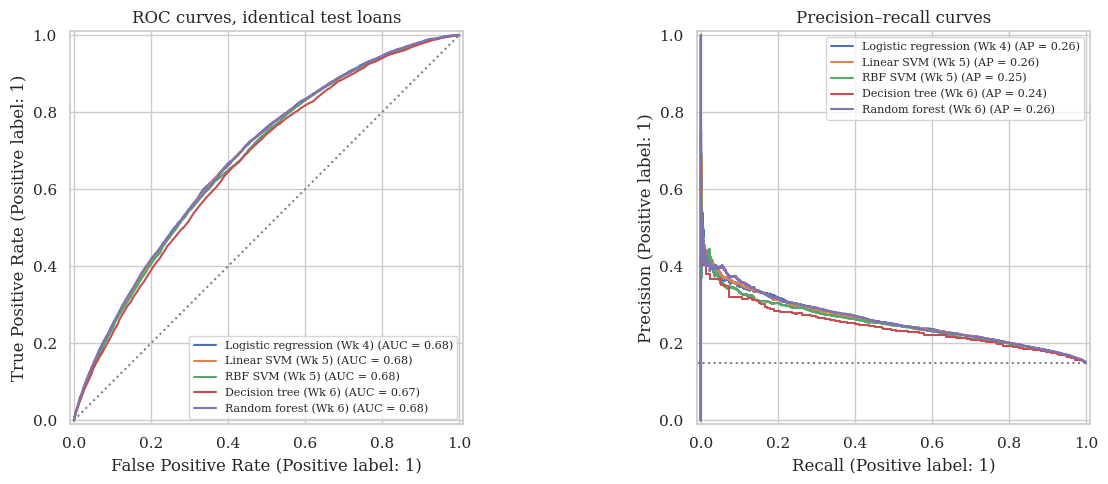

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (s, _, _) in models.items():
    RocCurveDisplay.from_predictions(y_te, s, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_predictions(y_te, s, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], ls=":", c="grey"); axes[0].set_title("ROC curves, identical test loans")
axes[1].axhline(y_te.mean(), ls=":", c="grey"); axes[1].set_title("Precision–recall curves")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "week6_final_comparison.png", dpi=200); plt.show()

## 5. Conclusions — *write after running*

* **Tree complexity:** at what depth does CV ROC-AUC peak, and how fast does the train−CV gap grow after that? Which splits does the depth-3 tree use first (likely `int_rate`/`grade` and `term`)? What does that say about how LendingClub's own pricing dominates?
* **Random forest:** compare train (in-sample), OOB, and test AUC. Is OOB ≈ test? How much did the forest improve on the single tree?
* **Importance:** do impurity and permutation importance agree? Note that MDI favors continuous variables, and correlated variables (`int_rate`, `grade`) share importance.
* **Final ranking (for Section 6 of the report):** which model wins on ROC-AUC/PR-AUC, and is the gap to the runner-up outside the bootstrap CI? If the CI includes zero, the models are effectively tied, and the more interpretable logistic regression is the better practical choice.
* **Expected vs unexpected:** did the nonlinear models (RBF SVM, forest) beat the linear ones by as much as expected? If not, explain why: mostly monotone credit relationships, and noisy outcomes driven by events after origination.